In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


# Smart MCQ Solver — Data Loading & EDA
Load train data and inspect basic structure before any preprocessing.

In [2]:
df=pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")

In [3]:
df.shape

(2000, 8)

In [4]:
df.head(3)

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C


#### Checking Null Values: 0 

In [5]:
df.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

#### Drop unused ID column

In [6]:
df=df.drop('id',axis=1)

## Duplicate Check
Checking duplicate prompts — kept intentionally (empirically improved leaderboard score vs. dropping them).

In [7]:
df.duplicated(subset='prompt').sum()

np.int64(242)

## Basic Feature Engineering: Length & Word Overlap
Prompt/option character lengths and prompt-option word overlap counts, used later for baseline heuristics and the ANN. Added directly to the entire train set as these features dont cause data leakage.

In [8]:
df['prompt_len']=df['prompt'].str.len()
for col in ['A','B','C','D','E']:
    df[f'{col}_len']=df[col].str.len()

def get_overlaps(row):
    prompt_words=set(row['prompt'].split())
    overlaps={}
    for col in ['A','B','C','D','E']:
        option_words=set(row[col].split())
        overlaps[f'{col}_overlap']=len(prompt_words & option_words)
    return pd.Series(overlaps)

overlaps_df=df.apply(get_overlaps,axis=1)
df=pd.concat([df,overlaps_df],axis=1)

## EDA: Answer Distribution
Checking class balance across A-E. Answers are slightly biased towards option B and least biased with option D.

Text(0.5, 1.0, 'Answer Distribution')

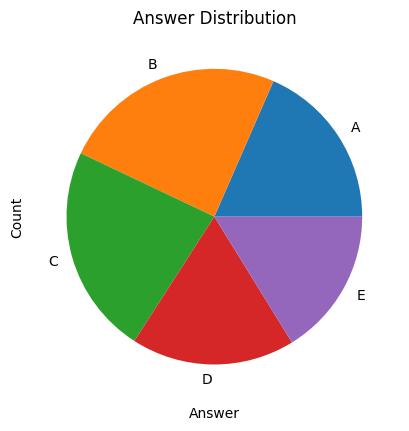

In [9]:
import matplotlib.pyplot as plt

answer=df['answer']
answer.value_counts().sort_index().plot(kind='pie')
plt.xlabel('Answer')
plt.ylabel('Count')
plt.title('Answer Distribution')

## EDA: Length Bias Check
Testing whether the correct answer is systematically the longest option.

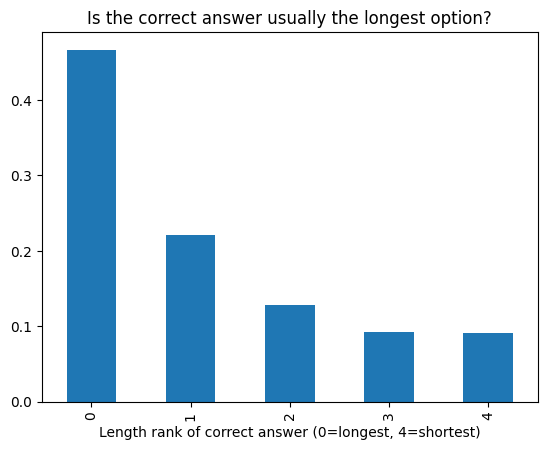

In [10]:
len_cols=['A_len','B_len','C_len','D_len','E_len']
lengths=df[len_cols].values
rank_of_correct=[]

for i,ans in enumerate(df['answer']):
    idx="ABCDE".index(ans)
    row_lengths=lengths[i]
    rank=(row_lengths > row_lengths[idx]).sum()
    rank_of_correct.append(rank)

pd.Series(rank_of_correct).value_counts(normalize=True).sort_index().plot(kind='bar')
plt.xlabel("Length rank of correct answer (0=longest, 4=shortest)")
plt.title("Is the correct answer usually the longest option?")
plt.show()

## EDA: Length Distributions
Sanity check on prompt/option length range — informs tokenizer max_length choice. So many of them have character length between 100 to 200. 

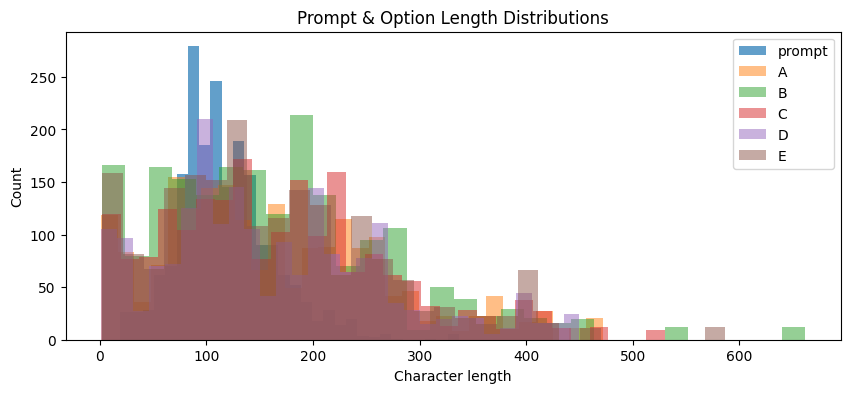

In [11]:
plt.figure(figsize=(10,4))
plt.hist(df['prompt_len'],bins=30,alpha=0.7,label='prompt')
for col in ['A','B','C','D','E']:
    plt.hist(df[f'{col}_len'],bins=30,alpha=0.5,label=col)
plt.xlabel('Character length')
plt.ylabel('Count')
plt.title('Prompt & Option Length Distributions')
plt.legend()
plt.show()

## EDA: Word Cloud
Most frequent terms across all prompts (stopwords + MCQ-boilerplate filtered out). Based on the common words, it is clear that the questions might be based on Science with predominant weightage to Physics followed by Biological Sciences.

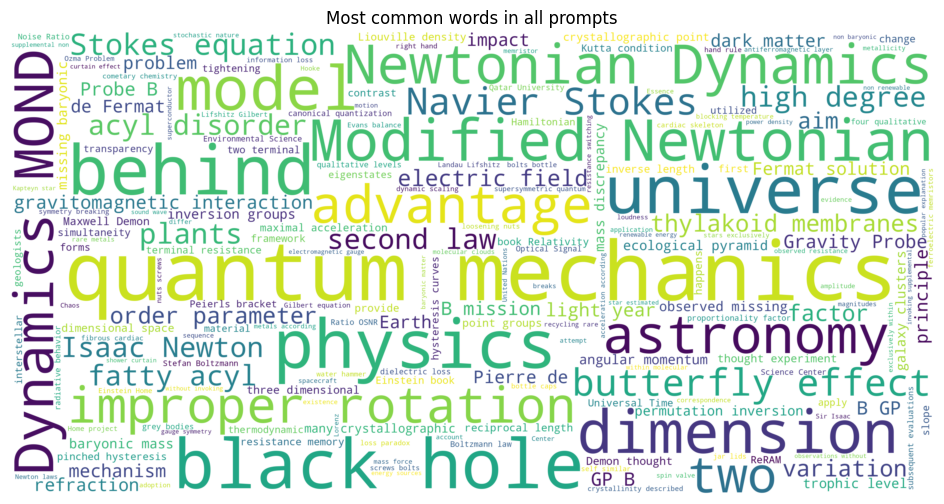

In [12]:
from wordcloud import WordCloud,STOPWORDS
import matplotlib.pyplot as plt

text=" ".join(df['prompt'].tolist())
custom_stopwords=[
    'following', 'listed', 'choices', 'choice', 'options', 'option',
    'correct', 'answer', 'answers', 'statement', 'statements',
    'identify', 'select', 'determine', 'pick', 'choose',
    'context', 'given', 'carefully', 'possible', 'best',
    'among', 'accurately', 'describes', 'describe', 'accurate',
    'based', 'relationship', 'role', 'reason', 'significance',
    'associated', 'used', 'term', 'distinction', 'defined', 'definition',
    'concept', 'measuring', 'origin', 'proposed', 'purpose',
    'focus', 'main', 'formation', 'processes'
]
wc=WordCloud(width=2000,height=1000,background_color='white',scale=2,stopwords=STOPWORDS.union(custom_stopwords),max_words=200).generate(text)

plt.figure(figsize=(12,6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Most common words in all prompts")
plt.show()

Separate Target Variable

In [13]:
answer=df['answer']
df=df.drop('answer',axis=1)

## Train/Validation Split
80/20 split, no stratification, fixed random_state.

In [14]:
from sklearn.model_selection import train_test_split

x_train,x_val,y_train,y_val=train_test_split(df,answer,train_size=0.8,random_state=1)

### Helper Functions : MAP@3, Other Scores and Scores to Labels mapping

In [15]:
def score_to_labels(scores,top1=False):
    labels=[]
    top1_labels=[]
    for score in scores:
        scored=np.argsort(score)[::-1][:3]
        top_3=[chr(65+i) for i in scored]
        labels.append(" ".join(top_3))
        top1_labels.append(chr(65+np.argsort(score)[::-1][0]))
    if not top1:
        return labels
    else:
        return top1_labels

In [16]:
def map_at_3(predictions,ground_truth):
    ap_scores=[]
    for pred, truth in zip(predictions, ground_truth):
        pred_list = pred.split()
        if truth in pred_list:
            ap_scores.append(1.0 / (pred_list.index(truth) + 1))
        else:
            ap_scores.append(0.0)
    return sum(ap_scores) / len(ap_scores)

In [17]:
from sklearn.metrics import accuracy_score,f1_score

def support_metrics(train_scores,val_scores):
    train_acc=accuracy_score(score_to_labels(train_scores,top1=True),y_train)
    val_acc=accuracy_score(score_to_labels(val_scores,top1=True),y_val)
    train_f1=f1_score(score_to_labels(train_scores,top1=True),y_train,average='macro')
    val_f1=f1_score(score_to_labels(val_scores,top1=True),y_val,average='macro')
    return train_acc,val_acc,train_f1,val_f1

## Additional Features: Special-Option Flags & Length Rank
Flagging "none/all of the above"-style options, and ranking options by length per row.

In [18]:
def special_option(text):
    text=str(text).lower()
    patterns=['none of the above','all of the above','none of these','all of these','both a and b','both a and c','both b and c','not applicable']
    return int(any(p in text for p in patterns))

In [19]:
for col in ['A','B','C','D','E']:
    x_train[f'{col}_is_special']=x_train[col].apply(special_option)
for col in ['A','B','C','D','E']:
    x_val[f'{col}_is_special']=x_val[col].apply(special_option)
x_train.head(12)

,prompt,A,B,C,D,E,prompt_len,A_len,B_len,C_len,...,A_overlap,B_overlap,C_overlap,D_overlap,E_overlap,A_is_special,B_is_special,C_is_special,D_is_special,E_is_special
0,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,142,307,258,222,...,6,5,8,8,5,0,0,0,0,0
816,Determine the correct option: What is the Penr...,The Penrose process is a mechanism through whi...,The Penrose process is a mechanism through whi...,The Penrose process is a mechanism through whi...,The Penrose process is a mechanism through whi...,The Penrose process is a mechanism through whi...,84,217,219,224,...,3,3,3,3,3,0,0,0,0,0
790,Which of the following is correct? What is the...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,113,230,233,233,...,3,3,3,2,2,0,0,0,0,0
361,Determine the correct option: Which of the fol...,The dimension of an object in a CW complex is ...,The dimension of an object in a CW complex is ...,The dimension of an object in a CW complex is ...,The dimension of an object in a CW complex is ...,The dimension of an object in a CW complex dep...,128,217,233,219,...,8,8,8,8,8,0,0,0,0,0
592,What is Minkowski space?,Minkowski space is a physical space where obje...,Minkowski space is a mathematical model that c...,Minkowski space is a mathematical model that c...,Minkowski space is a mathematical model that c...,Minkowski space is a physical space where obje...,24,103,205,131,...,2,2,2,2,2,0,0,0,0,0
1675,Determine the correct option: What is the defi...,Anatomy is the rarely used term that refers to...,Anatomy is a branch of morphology that deals w...,Anatomy is the study of the effects of externa...,Anatomy is the analysis of the patterns of the...,Anatomy is the study of the relationship betwe...,92,136,77,159,...,3,3,3,3,3,0,0,0,0,0
115,Determine the correct option: What is power de...,Power density is a measure of the amount of po...,Power density is a measure of the amount of po...,Power density is a measure of the amount of po...,Power density is a measure of the amount of po...,Power density is a measure of the amount of po...,191,411,545,408,...,10,8,9,8,9,0,0,0,0,0
1079,Choose the correct answer: What is the reason ...,The formation of stars occurs exclusively outs...,The low temperatures and high densities of mol...,The low temperatures and low densities of mole...,The high temperatures and low densities of mol...,The high temperatures and high densities of mo...,137,70,171,176,...,5,3,3,3,3,0,0,0,0,0
546,Determine the correct option: What is the orde...,None of the above.,A thin cylindrical plastic rod.,A condensed-matter collective field ψ.,The cosmic microwave background.,A component of the Higgs field.,135,18,31,38,...,1,0,0,0,1,1,0,0,0,0
336,Select the most accurate option: What is the S...,"The SI base unit of time is the week, which is...","The SI base unit of time is the second, which ...","The SI base unit of time is the hour, which is...","The SI base unit of time is the day, which is ...","The SI base unit of time is the minute, which ...",116,121,123,121,...,7,7,7,7,7,0,0,0,0,0


In [20]:
def length_rank_features(row):
    option_cols=['A','B','C','D','E']
    lengths={col:row[f'{col}_len'] for col in option_cols}
    sorted_options=sorted(option_cols,key=lambda col:lengths[col],reverse=True)
    ranks={}
    for rank,col in enumerate(sorted_options):
        ranks[f'{col}_len_rank']=rank
    return pd.Series(ranks)

rank_df_train=x_train.apply(length_rank_features,axis=1)
x_train=pd.concat([x_train,rank_df_train],axis=1)

rank_df_val=x_val.apply(length_rank_features,axis=1)
x_val=pd.concat([x_val,rank_df_val],axis=1)

## Experiment Tracking Setup (W&B)

In [21]:
!pip install wandb -q

In [22]:
import wandb
from kaggle_secrets import UserSecretsClient
import os

secrets=UserSecretsClient()
os.environ["WANDB_API_KEY"] = secrets.get_secret("WANDB_API_KEY")
wandb.login()
wandb_mode=True

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


# Baseline 1: Longest-Option Heuristic
Naive baseline — always guess the longest option first.

In [23]:
def len_scores(row):
    lengths=[row['A_len'],row['B_len'],row['C_len'],row['D_len'],row['E_len']]
    max_len=max(lengths)
    min_len=min(lengths)
    scores=[]
    for length in lengths:
        score=0
        if length==max_len:
            score=0.5
        elif length==min_len:
            score=0.2
        else:
            score=0.3
        scores.append(score)
    return scores

length_train_scores=x_train.apply(len_scores,axis=1).to_list()
length_labels=score_to_labels(length_train_scores)
length_map3=map_at_3(length_labels,y_train)
print(length_map3)

0.5320833333333334


In [24]:
length_val_scores=x_val.apply(len_scores,axis=1).to_list()
length_val_labels=score_to_labels(length_val_scores)
length_val_map3=map_at_3(length_val_labels,y_val)
length_val_map3

0.49666666666666665

In [25]:
from sklearn.metrics import accuracy_score,f1_score

len_train_acc,len_val_acc,len_train_f1,len_val_f1=support_metrics(length_train_scores,length_val_scores)

In [26]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="largestlen-baseline-metrics",id="largelen_v1",resume="allow")
    wandb.log({
        "map_at_3_train":length_map3,   
        "map_at_3_val":length_val_map3,
        "accuracy_at_train":len_train_acc,
        "accuracy_at_val":len_val_acc,
        "f1_at_train":len_train_f1,
        "f1_at_val":len_val_f1,
        "metric":"Longest-Length"
        })
    wandb.finish()

wandb: setting up run largelen_v1
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_105038-largelen_v1
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run largestlen-baseline-metrics
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/largelen_v1
wandb: uploading summary; updating run metadata
wandb: uploading summary; uploading wandb-metadata.json; uploading requirements.txt; uploading wandb-summary.json; uploading config.yaml
wandb: uploading summary
wandb: uploading history steps 51-51, summary
wandb: 
wandb: Run history:
wandb: accuracy_at_train ▁
wandb:   accuracy_at_val ▁
wandb:       f1_at_train ▁
wandb:         f1_at_val ▁
wandb:    map_at_3_train ▁
wandb:      map_at_3_val ▁
wandb: 
wandb: Run summary:
wandb: accuracy_at_train 0.4

# Baseline 2: TF-IDF Similarity
Scoring each option by prompt-option TF-IDF overlap.

In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

tfidf=TfidfVectorizer(sublinear_tf=True,ngram_range=(1,2))
all_text=x_train['prompt'].tolist()+x_train['A'].tolist()+x_train['B'].tolist()+x_train['C'].tolist()+x_train['D'].tolist()+x_train['E'].tolist()
tfidf.fit(all_text)

TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)

In [28]:
tfidf_train_scores=[]
for col in ['A', 'B', 'C', 'D', 'E']:
    combined=(x_train['prompt']+" "+x_train[col]).to_list()
    scores=tfidf.transform(combined).sum(axis=1)
    tfidf_train_scores.append(np.asarray(scores).flatten())
tfidf_train_scores=np.array(tfidf_train_scores).T

In [29]:
tfidf_val_scores=[]
for col in ['A', 'B', 'C', 'D', 'E']:
    combined=(x_val['prompt']+" "+x_val[col]).to_list()
    scores=tfidf.transform(combined).sum(axis=1)
    tfidf_val_scores.append(np.asarray(scores).flatten())
tfidf_val_scores=np.array(tfidf_val_scores).T

In [30]:
tfidf_train_labels=score_to_labels(tfidf_train_scores,top1=False)
tfidf_train_map3=map_at_3(tfidf_train_labels,y_train)
print(tfidf_train_map3)

tfidf_val_labels=score_to_labels(tfidf_val_scores,top1=False)
tfidf_val_map3=map_at_3(tfidf_val_labels,y_val)
print(tfidf_val_map3)

0.5355208333333333
0.5320833333333334


In [31]:
tfidf_train_acc,tfidf_val_acc,tfidf_train_f1,tfidf_val_f1=support_metrics(tfidf_train_scores,tfidf_val_scores)

In [32]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="tfidf-baseline-metrics",id="tfidf_v1",resume="allow")
    wandb.log({
        "map_at_3_train":tfidf_train_map3,   
        "map_at_3_val":tfidf_val_map3,
        "accuracy_at_train":tfidf_train_acc,
        "accuracy_at_val":tfidf_val_acc,
        "f1_at_train":tfidf_train_f1,
        "f1_at_val":tfidf_val_f1,
        "vectorizer":"TfidfVectorizer",
        "sublinear_tf":True})
    wandb.finish()

wandb: setting up run tfidf_v1
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_105049-tfidf_v1
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run tfidf-baseline-metrics
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/tfidf_v1
wandb: updating run metadata
wandb: uploading wandb-metadata.json; uploading requirements.txt; uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb: accuracy_at_train ▁
wandb:   accuracy_at_val ▁
wandb:       f1_at_train ▁
wandb:         f1_at_val ▁
wandb:    map_at_3_train ▁
wandb:      map_at_3_val ▁
wandb: 
wandb: Run summary:
wandb: accuracy_at_train 0.34813
wandb:   accuracy_at_val 0.3525
wandb:       f1_at_train 0.34639
wandb:         f1_at_val 0.35202
wandb:    map_at_3_t

In [33]:
import torch
import numpy as np
import random

seed=42
torch.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

# Baseline 3 : Word2Vec Embeddings
Training a lightweight Word2Vec model on train text for prompt-option cosine similarity scoring, feeding into the ANN's input features.

In [34]:
from gensim.models import Word2Vec
np.random.seed(1)
from numpy.random import seed
seed(1)

sentences=[text.split() for text in all_text]
word2vec=Word2Vec(sentences,vector_size=10,window=1,min_count=1,seed=1,workers=1,epochs=10)

In [35]:
option_cols=['A','B','C','D','E']
def sentence_embedding(text):
    words=text.split()
    embedding=[word2vec.wv[word] for word in words if word in word2vec.wv]
    if len(embedding)==0:
        return np.zeros(word2vec.vector_size)
    return np.mean(embedding,axis=0)

In [36]:
prompts=np.vstack(x_train['prompt'].apply(sentence_embedding))
w2v_train_scores=[]

for col in option_cols:
    option_matrix=np.vstack(x_train[col].apply(sentence_embedding))
    scores=np.diag(cosine_similarity(prompts,option_matrix))
    w2v_train_scores.append(scores)
w2v_train_scores=np.array(w2v_train_scores).T

In [37]:
prompts=np.vstack(x_train['prompt'].apply(sentence_embedding))
w2v_train_scores=[]

for col in option_cols:
    option_matrix=np.vstack(x_train[col].apply(sentence_embedding))
    scores=np.diag(cosine_similarity(prompts,option_matrix))
    w2v_train_scores.append(scores)
w2v_train_scores=np.array(w2v_train_scores).T

In [38]:
val_prompts=np.vstack(x_val['prompt'].apply(sentence_embedding))
w2v_val_scores=[]

for col in option_cols:
    option_matrix=np.vstack(x_val[col].apply(sentence_embedding))
    scores=np.diag(cosine_similarity(val_prompts,option_matrix))
    w2v_val_scores.append(scores)
w2v_val_scores=np.array(w2v_val_scores).T

In [39]:
w2v_train_labels=score_to_labels(w2v_train_scores)
w2v_train_map3=map_at_3(w2v_train_labels,y_train)
print(w2v_train_map3)

w2v_val_labels=score_to_labels(w2v_val_scores)
w2v_val_map3=map_at_3(w2v_val_labels,y_val)
print(w2v_val_map3)

0.3885416666666666
0.37416666666666665


In [40]:
w2v_train_acc,w2v_val_acc,w2v_train_f1,w2v_val_f1=support_metrics(w2v_train_scores,w2v_val_scores)

if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="word2vec-baseline-metrics",id="w2v_v1", resume="allow")
    wandb.log({
        "map_at_3_train":w2v_train_map3,   
        "map_at_3_val":w2v_val_map3,
        "accuracy_at_train":w2v_train_acc,
        "accuracy_at_val":w2v_val_acc,
        "f1_at_train":w2v_train_f1,
        "f1_at_val":w2v_val_f1,
        "embedding_model":"Word2Vec",
        "vector_size":20,
         "window":1,
         "min_count":1})
    wandb.finish()

wandb: setting up run w2v_v1
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_105121-w2v_v1
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run word2vec-baseline-metrics
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/w2v_v1
wandb: uploading summary; updating run metadata
wandb: uploading summary
wandb: uploading history steps 73-73, summary
wandb: 
wandb: Run history:
wandb: accuracy_at_train ▁
wandb:   accuracy_at_val ▁
wandb:       f1_at_train ▁
wandb:         f1_at_val ▁
wandb:    map_at_3_train ▁
wandb:      map_at_3_val ▁
wandb:         min_count ▁
wandb:       vector_size ▁
wandb:            window ▁
wandb: 
wandb: Run summary:
wandb: accuracy_at_train 0.22687
wandb:   accuracy_at_val 0.21
wandb:   embedding_model Word2Vec
wand

In [41]:
cols=x_train.columns
cols=cols.drop(['prompt',"A","B","C","D",'E'])

In [42]:
len(cols)

21

#### Label Encoding

In [43]:
label_map={"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}

y_train_idx=y_train.map(label_map).values if y_train.dtype=='object' else y_train.values
y_val_idx=y_val.map(label_map).values if y_val.dtype=='object' else y_val.values

In [44]:
from torch.utils.data import TensorDataset,DataLoader
from sklearn.preprocessing import StandardScaler

ss=StandardScaler()

x_train_t=torch.tensor(ss.fit_transform(np.concatenate((tfidf_train_scores,np.array(length_train_scores),w2v_train_scores,x_train[cols].values),axis=1)),dtype=torch.float32)
x_val_t=torch.tensor(ss.transform(np.concatenate((tfidf_val_scores,np.array(length_val_scores),w2v_val_scores,x_val[cols].values),axis=1)),dtype=torch.float32)
y_train_t=torch.tensor(y_train_idx,dtype=torch.long)
y_val_t=torch.tensor(y_val_idx,dtype=torch.long)

# Baseline 4 (MODEL 1): Custom ANN (MCQANN)
Small feed-forward network over TF-IDF + length + Word2Vec + other engineered features.

In [45]:
from torch.utils.data import TensorDataset,DataLoader

train_ds=TensorDataset(x_train_t,y_train_t)
train_loader=DataLoader(train_ds,batch_size=16,shuffle=True)

In [46]:
import torch.nn as nn

class MCQANN(nn.Module):
    def __init__(self,input_dim,num_choices=5,hidden_dim=32):
        super().__init__()
        self.net=nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim,hidden_dim//2),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(hidden_dim//2,num_choices)
        )
    def forward(self,x):
        return self.net(x)

model=MCQANN(input_dim=x_train_t.shape[1])

In [47]:
wandb.init(project="24f2002314-t22026",name="MCQ-ANN-scaled",id="ann_version_scaled2",resume="allow")
wandb.log({
        "lr":3e-4,   
        "weight_decay":1e-4,
        "epochs": 400,
        "patience": 15,
        "hidden_dimension":16,
        "batch_size": 32,
        "architecture": "MCQANN",
        "input_dim": x_train_t.shape[1],})

wandb: setting up run ann_version_scaled2
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_105130-ann_version_scaled2
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run MCQ-ANN-scaled
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/ann_version_scaled2


In [48]:
import copy

criteria=nn.CrossEntropyLoss()
EPOCHS=400
optimizer=torch.optim.Adam(model.parameters(),lr=3e-4,weight_decay=1e-4)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=1e-6)
device="cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

best_val_loss=float('inf')
patience=15
patience_count=0
best_val_map3=0
for epoch in range(EPOCHS):
    model.train()
    total_loss=0
    for x,y in train_loader:
        x,y=x.to(device),y.to(device)
        optimizer.zero_grad()
        output=model(x)
        loss=criteria(output,y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.0)
        optimizer.step()
        total_loss+=loss.item()
    scheduler.step()

    if epoch%1==0:
        model.eval()
        with torch.no_grad():
            val_ds=x_val_t.to(device)
            val_out=model(val_ds)
            val_loss=criteria(val_out,y_val_t.to(device))
            val_acc=(val_out.argmax(dim=1).cpu()==y_val_t).float().mean()
            val_scores=val_out.cpu().numpy()
            val_labels=score_to_labels(val_scores,top1=False)
            val_map3=map_at_3(val_labels, y_val)
            avg_train_loss=total_loss/len(train_loader)
        print(f'Epoch :{epoch} - train loss : {avg_train_loss:.4f} val loss : {val_loss:.4f} val_acc={val_acc:.4f} val_map3={val_map3:.4f}')
        wandb.log({
            "epoch": epoch,
            "train_loss": avg_train_loss,
            "val_loss": val_loss.item(),
            "val_acc": val_acc.item(),
            "val_map3": val_map3
        })
            
    if val_map3>=best_val_map3+1e-4:
        best_val_loss=val_loss
        best_val_map3=val_map3
        patience_count=0
        best_state=copy.deepcopy(model.state_dict())
    else:
        patience_count+=1
        if patience_count>=patience:
            print(f"Early stopping at epoch {epoch}")
            break
model.load_state_dict(best_state)

Epoch :0 - train loss : 1.6275 val loss : 1.5905 val_acc=0.2500 val_map3=0.4079
Epoch :1 - train loss : 1.5951 val loss : 1.5630 val_acc=0.3050 val_map3=0.4854
Epoch :2 - train loss : 1.5635 val loss : 1.5393 val_acc=0.3300 val_map3=0.5121
Epoch :3 - train loss : 1.5368 val loss : 1.5093 val_acc=0.3800 val_map3=0.5575
Epoch :4 - train loss : 1.5014 val loss : 1.4744 val_acc=0.3875 val_map3=0.5775
Epoch :5 - train loss : 1.4655 val loss : 1.4405 val_acc=0.4275 val_map3=0.5988
Epoch :6 - train loss : 1.4517 val loss : 1.4203 val_acc=0.4125 val_map3=0.5967
Epoch :7 - train loss : 1.4330 val loss : 1.3938 val_acc=0.4200 val_map3=0.5983
Epoch :8 - train loss : 1.3880 val loss : 1.3640 val_acc=0.4450 val_map3=0.6221
Epoch :9 - train loss : 1.3924 val loss : 1.3441 val_acc=0.4700 val_map3=0.6375
Epoch :10 - train loss : 1.3798 val loss : 1.3202 val_acc=0.4800 val_map3=0.6496
Epoch :11 - train loss : 1.3836 val loss : 1.3097 val_acc=0.4775 val_map3=0.6446
Epoch :12 - train loss : 1.3608 val lo

<All keys matched successfully>

In [49]:
device='cuda' if torch.cuda.is_available() else 'cpu'
model.eval()
with torch.no_grad():
    predictions=model(x_val_t.to(device)).argmax(dim=1).cpu().numpy()
    targets=y_val_t.to(device).cpu().numpy()

accuracy_ann=accuracy_score(targets,predictions)
print(f"Accuracy: {accuracy_ann}")

Accuracy: 0.8675


In [50]:
wandb.run.summary["best_val_loss"]=best_val_loss.item()
wandb.run.summary["best_val_map3"]=val_map3   
wandb.run.summary["stopped_epoch"]=epoch
torch.save(best_state,"best_model.pt")
artifact=wandb.Artifact("mcq_ann_best_model",type="model")
artifact.add_file("best_model.pt")
wandb.log_artifact(artifact)
wandb.finish()

wandb: uploading artifact mcq_ann_best_model; updating run metadata
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: uploading history steps 1119-1163, summary, console lines 80-126
wandb: 
wandb: Run history:
wandb:       batch_size ▁
wandb:            epoch ▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▇▇▇▇▇█
wandb:           epochs ▁
wandb: hidden_dimension ▁
wandb:        input_dim ▁
wandb:               lr ▁
wandb:         patience ▁
wandb:       train_loss █▇▇▇▆▆▅▅▅▅▄▄▄▄▃▃▃▂▃▃▂▂▂▂▂▂▂▂▂▂▁▂▂▂▁▂▂▂▁▁
wandb:          val_acc ▁▁▂▂▃▃▃▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇▇▇▇▇▇██████
wandb:         val_loss ███▇▆▆▆▆▆▅▅▅▄▄▄▄▄▄▃▃▃▃▃▃▂▂▂▂▂▂▂▂▂▂▂▁▁▁▁▁
wandb:               +2 ...
wandb: 
wandb: Run summary:
wandb: Batch Normalisation True
wandb:        architecture MCQANN
wandb:          batch_size 32
wandb:       best_val_loss 0.5247
wandb:       best_val_map3 0.90333
wandb:               epoch 124
wandb:              epochs 400
wandb:    hidden_dimension 16
wandb:           input

### Building the dataset

In [51]:
from datasets import Dataset

label_map={'A':0,'B':1,'C':2,'D':3,'E':4}

x_train['label']=y_train.map(label_map)
x_val['label']=y_val.map(label_map)
train_dataset=Dataset.from_pandas(x_train.reset_index(drop=True))
val_dataset=Dataset.from_pandas(x_val.reset_index(drop=True))

# Transformer Fine-Tuning (Pretrained Models 2 and 3: Electra & RoBERTa)
Multiple-choice fine-tuning on the augmented training set (duplicates kept, options shuffled/relabeled). This is the core model for final predictions.

In [52]:
from transformers import AutoModelForMultipleChoice,AutoTokenizer,TrainingArguments,Trainer
import torch

model_name1='google/electra-base-discriminator'
tokeniser1=AutoTokenizer.from_pretrained(model_name1)
model1=AutoModelForMultipleChoice.from_pretrained(model_name1,ignore_mismatched_sizes=True)

model_name2='roberta-base'
tokeniser2=AutoTokenizer.from_pretrained(model_name2)
model2=AutoModelForMultipleChoice.from_pretrained(model_name2,ignore_mismatched_sizes=True)

def preprocessing(data,tokeniser):
    prompts=[[p]*5 for p in data['prompt']]
    options=[[data[o][i] for o in ['A','B','C','D','E']] for i in range(len(data['prompt']))]
    prompts=sum(prompts,[])
    options=sum(options,[])
    processed=tokeniser(prompts,options,truncation=True,max_length=256,padding='max_length')
    result={k:[v[i:i+5] for i in range(0,len(v),5)] for k,v in processed.items()}
    if "label" in data:
         result["label"]=data["label"]

    return result

processed_train1=train_dataset.map(lambda x:preprocessing(x,tokeniser1),batched=True,remove_columns=train_dataset.column_names)
processed_val1=val_dataset.map(lambda x:preprocessing(x,tokeniser1),batched=True,remove_columns=val_dataset.column_names)
processed_train2=train_dataset.map(lambda x:preprocessing(x,tokeniser2),batched=True,remove_columns=train_dataset.column_names)
processed_val2=val_dataset.map(lambda x:preprocessing(x,tokeniser2),batched=True,remove_columns=val_dataset.column_names)

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/440M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

... (10 outputs left out)

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

In [53]:
from sklearn.metrics import f1_score

def compute_metrics(eval_pred):
    logits,labels=eval_pred
    top3=np.argsort(-logits,axis=1)[:,:3]
    ap=[1.0/(list(row).index(l)+1) if l in row else 0.0 for row,l in zip(top3,labels)]
    acc=(np.argmax(logits, axis=1)==labels).mean()
    preds=np.argmax(logits,axis=1)
    f1_macro=f1_score(labels,preds,average="macro")
    return {"map_at_3":np.mean(ap),"accuracy":acc,"f1_macro":f1_macro}

In [54]:
processed_train1.set_format(type="torch",columns=["input_ids","attention_mask","label"])
processed_val1.set_format(type="torch",columns=["input_ids","attention_mask","label"])

processed_train2.set_format(type="torch",columns=["input_ids","attention_mask","label"])
processed_val2.set_format(type="torch",columns=["input_ids","attention_mask","label"])

train_args1=TrainingArguments(output_dir="./electra-base-mcq",learning_rate=4e-5,eval_strategy="epoch",gradient_checkpointing=False,save_strategy="epoch",num_train_epochs=6,warmup_steps=500,remove_unused_columns=False,max_grad_norm=1.0,
                             fp16=False,weight_decay=0.01,logging_steps=10,metric_for_best_model="map_at_3",per_device_train_batch_size=8,per_device_eval_batch_size=8,load_best_model_at_end=True)

trainer1=Trainer(model=model1,args=train_args1,train_dataset=processed_train1,eval_dataset=processed_val1,compute_metrics=compute_metrics)
trainer1.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Map At 3,Accuracy,F1 Macro
1,3.150310,3.112656,0.704167,0.550000,0.553020
2,1.840284,1.624896,0.907083,0.840000,0.837935
3,1.019052,0.691109,0.978333,0.965000,0.964150
4,0.252928,0.206567,0.988750,0.982500,0.983806
5,0.117943,0.117028,0.998750,0.997500,0.996914
6,0.017257,0.031826,1.000000,1.000000,1.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (5 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['electra.embeddings.LayerNorm.weight', 'electra.embeddings.LayerNorm.bias', 'electra.encoder.layer.0.attention.output.LayerNorm.weight', 'electra.encoder.layer.0.attention.output.LayerNorm.bias', 'electra.encoder.layer.0.output.LayerNorm.weight', 'electra.encoder.layer.0.output.LayerNorm.bias', 'electra.encoder.layer.1.attention.output.LayerNorm.weight', 'electra.encoder.layer.1.attention.output.LayerNorm.bias', 'electra.encoder.layer.1.output.LayerNorm.weight', 'electra.encoder.layer.1.output.LayerNorm.bias', 'electra.encoder.layer.2.attention.output.LayerNorm.weight', 'electra.encoder.layer.2.attention.output.LayerNorm.bias', 'electra.encoder.layer.2.output.LayerNorm.weight', 'electra.encoder.layer.2.output.LayerNorm.bias', 'electra.encoder.layer.3.attention.output.LayerNorm.weight', 'electra.encoder.layer.3.attention.output.LayerNorm.bias', 'electra.encoder.layer.3.output.LayerNorm.weight', 'electra.encoder.layer.3.output.Laye

TrainOutput(global_step=600, training_loss=1.2928895960624018, metrics={'train_runtime': 1181.0375, 'train_samples_per_second': 8.128, 'train_steps_per_second': 0.508, 'total_flos': 6314608631808000.0, 'train_loss': 1.2928895960624018, 'epoch': 6.0})

### Training Loop

In [55]:
train_args2=TrainingArguments(output_dir="./roberta-base-mcq",learning_rate=3e-5,eval_strategy="epoch",gradient_checkpointing=False,save_strategy="epoch",num_train_epochs=5,warmup_steps=500,remove_unused_columns=False,max_grad_norm=1.0,
                             fp16=False,weight_decay=0.01,logging_steps=10,metric_for_best_model="map_at_3",per_device_train_batch_size=8,per_device_eval_batch_size=8,load_best_model_at_end=True)

trainer2=Trainer(model=model2,args=train_args2,train_dataset=processed_train2,eval_dataset=processed_val2,compute_metrics=compute_metrics)
trainer2.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Map At 3,Accuracy,F1 Macro
1,3.231688,3.215526,0.594167,0.442500,0.440295
2,2.460549,1.991847,0.777500,0.665000,0.660432
3,1.253563,0.864355,0.957917,0.932500,0.932968
4,0.441957,0.288992,0.993333,0.987500,0.987020
5,0.186725,0.168022,0.989583,0.980000,0.978746


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (3 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=500, training_loss=1.780811156988144, metrics={'train_runtime': 997.9385, 'train_samples_per_second': 8.017, 'train_steps_per_second': 0.501, 'total_flos': 5262173859840000.0, 'train_loss': 1.780811156988144, 'epoch': 5.0})

### Validation Predictions & Logging

In [56]:
val_results1=trainer1.predict(processed_val1)
val_results2=trainer2.predict(processed_val2)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


In [57]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="electra-final",id="electra-base-final",resume="allow")
    wandb.log({   
        "metrics":val_results1.metrics,
        "MODEL":"ELECTRA-BASE-DISCRIMINATOR",
        "epochs":6,
        "learning_rate":4e-5,
        "warm-up":500,
        "weight_decay":0.01
         })
    wandb.finish()

wandb: setting up run electra-base-final
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_112939-electra-base-final
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run electra-final
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/electra-base-final
wandb: updating run metadata
wandb: uploading history steps 1-1, summary
wandb: 
wandb: Run history:
wandb:        epochs ▁
wandb: learning_rate ▁
wandb:       warm-up ▁
wandb:  weight_decay ▁
wandb: 
wandb: Run summary:
wandb:         MODEL ELECTRA-BASE-DISCRIM...
wandb:        epochs 6
wandb: learning_rate 4e-05
wandb:       warm-up 500
wandb:  weight_decay 0.01
wandb: 
wandb: 🚀 View run electra-final at: https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/

In [58]:
if wandb_mode==True:
    wandb.init(project="24f2002314-t22026",name="roberta-final",id="roberta-base-final",resume="allow")
    wandb.log({   
        "metrics":val_results2.metrics,
        "MODEL":"ROBERTA-BASE",
        "epochs":5,
        "learning_rate":3e-5,
        "warm-up":500,
        "weight_decay":0.01
         })
    wandb.finish()

wandb: setting up run roberta-base-final
wandb: Tracking run with wandb version 0.26.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_112941-roberta-base-final
wandb: Run `wandb offline` to turn off syncing.
wandb: Resuming run roberta-final
wandb: ⭐️ View project at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026
wandb: 🚀 View run at https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/roberta-base-final
wandb: updating run metadata
wandb: uploading history steps 1-1, summary
wandb: 
wandb: Run history:
wandb:        epochs ▁
wandb: learning_rate ▁
wandb:       warm-up ▁
wandb:  weight_decay ▁
wandb: 
wandb: Run summary:
wandb:         MODEL ROBERTA-BASE
wandb:        epochs 5
wandb: learning_rate 3e-05
wandb:       warm-up 500
wandb:  weight_decay 0.01
wandb: 
wandb: 🚀 View run roberta-final at: https://wandb.ai/24f2002314-indian-institute-of-technology-madras/24f2002314-t22026/runs/robert

## Obtained Results on Various Baselines

In [59]:
comparison = pd.DataFrame({
    'Model': ['Longest-Length', 'TF-IDF', 'Word2Vec', 'Custom ANN', 'Electra-base'],
    'Val MAP@3': [length_val_map3, tfidf_val_map3, w2v_val_map3, best_val_map3, 
                  val_results1.metrics['test_map_at_3']],
    'Val Accuracy': [len_val_acc, tfidf_val_acc, w2v_val_acc,accuracy_ann,
                     val_results1.metrics['test_accuracy']]
})
comparison

,Model,Val MAP@3,Val Accuracy
0,Longest-Length,0.496667,0.3825
1,TF-IDF,0.532083,0.3525
2,Word2Vec,0.374167,0.2100
3,Custom ANN,0.915833,0.8675
4,Electra-base,1.000000,1.0000


In [60]:
print(val_results1.metrics.keys())

dict_keys(['test_loss', 'test_map_at_3', 'test_accuracy', 'test_f1_macro', 'test_runtime', 'test_samples_per_second', 'test_steps_per_second'])


## Test Dataset Preprocessing and creating inference of the Selected Model

In [61]:
test=pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
test['prompt_len']=test['prompt'].str.len()
for col in ['A','B','C','D','E']:
    test[f'{col}_len']=test[col].str.len()

def get_overlaps(row):
    prompt_words=set(row['prompt'].split())
    overlaps={}
    for col in ['A','B','C','D','E']:
        option_words=set(row[col].split())
        overlaps[f'{col}_overlap']=len(prompt_words & option_words)
    return pd.Series(overlaps)

overlaps_test=test.apply(get_overlaps,axis=1)
test=pd.concat([test,overlaps_test],axis=1)

test_dataset=Dataset.from_pandas(test)
processed_test1=test_dataset.map(lambda x:preprocessing(x,tokeniser1),batched=True,remove_columns=test_dataset.column_names)
processed_test2=test_dataset.map(lambda x:preprocessing(x,tokeniser2),batched=True,remove_columns=test_dataset.column_names)

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [62]:
test_results1=trainer1.predict(processed_test1)
logits1=test_results1.predictions
letters=np.array(["A","B","C","D","E"])
top3=np.argsort(logits1,axis=1)[:, ::-1][:, :3]
top3=[" ".join(letters[row]) for row in top3]
print(top3[:10])

['A B D', 'B D E', 'B E D', 'E C D', 'C B D', 'D A B', 'E C B', 'B E A', 'C D B', 'B E A']


In [63]:
submission=pd.DataFrame({'id':test['id'],'Prediction':top3})
submission.to_csv('submission_model1_w2v.csv',index=False)
print("Model submission saved!")
print(submission.head())

Model submission saved!
   id Prediction
0   1      A B D
1   2      B D E
2   3      B E D
3   4      E C D
4   5      C B D
